In [ ]:
import numpy as np
from math import exp, log
import json
from scipy.integrate import solve_ivp

with open('materiais.json', 'r') as materiais:
    componentes = json.load(materiais)

In [ ]:
def SRK(massa, massa_total, temperatura, pressão, componentes):
        
    y = {}
    for componente in componentes:
        y[componente] = massa[componente]/massa_total
    
    R = 8.314 # J/mol.K

    alfa = {}
    aci = {}
    ai = {}
    bi = {}

    for componente in componentes:
        alfa[componente]=(1+(0.480+(1.574*componentes[componente]["w"])-(0.176*componentes[componente]["w"]**2))*(1-((temperatura/componentes[componente]["Tc"])**0.5)))**2
        aci[componente]=0.42748*(((R**2)*(componentes[componente]["Tc"]**2.5))/componentes[componente]["Pc"])
        ai[componente]=alfa[componente]*aci[componente]
        bi[componente]=0.008664*R*componentes[componente]["Tc"]/componentes[componente]["Pc"]
    
    #Regra de mistura
    aij = {}
    a_mix = 0
    b_mix = 0
    for componente1 in componentes:
        for componente2 in componentes:
            aij[(componente1, componente2)] = y[componente1]*y[componente2]*((ai[componente1]*ai[componente2])**0.5) #* (1 - kij.get((i, j), kij.get((j, i), 0))) - parametro considerado 0 por simplificação
            a_mix += aij[(componente1, componente2)] 
        b_mix += y[componente1]*bi[componente1]

    
    A=(a_mix*pressão)/((R**2)*(temperatura**2))
    B=(b_mix*pressão)/(R*temperatura)
    
    #coeffs = [1, -(1 - B), A - 2*B - 3*B**2, -(A*B - B**2 - B**3)]
    coeffs = [1, -1, (A - B - B**2), -(A * B)]
    Z_roots = np.roots(coeffs)
    Z = np.real(Z_roots[np.isreal(Z_roots)])[0]

    return alfa, aci, ai, bi, aij, a_mix, b_mix, A, B, Z

In [ ]:
def fugacidade(massa, massa_total, parametros, componentes):
    y = {}
    for componente in componentes:
        y[componente] = massa[componente]/massa_total
    
    phi = {}
    for componente1 in componentes:
        term1 = parametros["bi"][componente1] * (parametros["Z"] - 1) / parametros["b_mix"]
        term2 = np.log(parametros["Z"] - parametros["B"])
        term3 = parametros["A"] / parametros["B"]
        sum_term4 = 0
        for componente2 in componentes:
            sum_term4 += y[componente2]*np.sqrt(parametros["ai"][componente1]*parametros["ai"][componente2])
        
        term4 = (2* sum_term4)/parametros["a_mix"]
        term5 = np.log((parametros["Z"]+parametros["B"])/parametros["Z"])
        ln_phi_i = term1 - term2 - term3 * (term4 - (parametros["bi"][componente1]/parametros["b_mix"]))*term5
        phi[componente1] = np.exp(ln_phi_i)
    
    return phi

In [ ]:
def capacidade_calorífica(componentes, temperatura):
    R = 8.314
    cp = {}
    for componente in componentes:
        cp[componente] = R*(componente["A"]+(componente["B"]*temperatura)+(componente["C"]*(temperatura**2))+(componente["D"]*(temperatura**-2))+(componente["E"]*(temperatura**3)))
    
    return cp

In [ ]:
def volume_SRK(pressao, temperatura, parametros):
    R = 8.314

    coef1 = pressao
    coef2 = -(R * temperatura)
    coef3 = pressao * parametros["b_mix"] - R * temperatura * parametros["b_mix"] - parametros["a_mix"]
    coef4 = -parametros["a_mix"] * parametros["b_mix"]

    # Coeficientes do polinômio cúbico
    coeficientes = [coef1, coef2, coef3, coef4]
    
    # Encontrar as raízes do polinômio cúbico
    roots = np.roots(coeficientes)
    
    # Filtrar as raízes reais e positivas
    real_roots = [root for root in roots if np.isreal(root) and root > 0]
    
    if len(real_roots) == 0:
        raise ValueError("Não foram encontradas raízes reais e positivas.")
    
    # Retornar a menor raiz real e positiva
    return np.real(min(real_roots))

In [ ]:
def viscosidade(componentes, massa, massa_total,temperatura):
    y = {}
    visc = {}
    visc_mix = 0

    for componente in componentes:
        y[componente] = massa[componente]/massa_total
        visc[componente] = (componentes[componente]["constantes_de_viscosidade"][0]*(temperatura**componentes[componente]["constantes_de_viscosidade"][1]))/(1+(componentes[componente]["constantes_de_viscosidade"][2]/temperatura)+(componentes[componente]["constantes_de_viscosidade"][3]/temperatura**2))
        visc_mix += y[componente]*visc[componente]

    return visc_mix

In [ ]:
def cinetica(vazao_molar, temperatura, pressao, componentes, parametros):
    
    vazao_molar_total = sum(vazao_molar.values())
    vazao_massica = {}
    for componente in componentes:
        vazao_massica[componente] = componentes[componente]["MM"] * vazao_molar[componente]

    vazao_massica_total = sum(vazao_massica.values())
    
    vazao_volumetrica = vazao_molar_total * parametros["Z"]*8.314*temperatura*pressao

    rt=8.314*temperatura
    ka=1.88e8*exp(-113711/rt)
    kb=1.16e10*exp(-126523/rt)
    kc=7.08e4*exp(-68252/rt)
    KH2O=3.8e-10*exp(80876/rt)
    Kpa=exp((1.183e4/temperatura)-26.061)
    Kpb=exp((-4.773e3/temperatura)+4.672)
    Kpc=Kpa*Kpb;
    KCO=7.99e-7*exp(58700/rt)
    KCO2=1.02e-7*exp(68000/rt)
    RKH2=KH2O/(5.64e-11*exp(105600/rt))

    phi=fugacidade(vazao_massica, vazao_massica_total, parametros, componentes)
    pressoes_parciais = {}

    for componente in componentes:
        fracao_molar = vazao_molar[componente] / vazao_molar_total
        pressoes_parciais[componente] = fracao_molar * phi[componente] * (pressao / 101325)

    r1=(ka*KCO*((pressoes_parciais["CO"]*(pressoes_parciais["H2"]**1.5))-(pressoes_parciais["CH3OH"]/(Kpa*(pressoes_parciais["H2"]**0.5)))))/((1+(KCO*pressoes_parciais["CO"]))*(1+(RKH2*(pressoes_parciais["H2"]**0.5))+(KH2O*pressoes_parciais["H2O"])))
    r2=(kb*KCO2*((pressoes_parciais["CO"]*pressoes_parciais["H2"])-((pressoes_parciais["CO"]*pressoes_parciais["H2O"])/Kpb)))/((1+(KCO2*pressoes_parciais["CO2"]))*(1+(RKH2*(pressoes_parciais["H2"]**0.5))+(KH2O*pressoes_parciais["H2O"])))
    r3=(kc*KCO2*((pressoes_parciais["CO2"]*(pressoes_parciais["H2"]**1.5))-((pressoes_parciais["H2O"]*pressoes_parciais["CH3OH"])/(Kpc*(pressoes_parciais["H2"]**1.5)))))/((1+(KCO2*pressoes_parciais["CO2"]))*(1+(RKH2*(pressoes_parciais["H2"]**0.5))+(KH2O*pressoes_parciais["H2O"])))

    taxa_de_geração = {}

    taxa_de_geração["CO"] = (-r1)+(r2)
    taxa_de_geração["H2"]=(-2*r1)+(-r2)+(-3*r3)
    taxa_de_geração["CH3OH"]=(r1+r3)
    taxa_de_geração["CH4"]=(0)
    taxa_de_geração["H2O"]=(r2+r3)
    taxa_de_geração["CO2"]=(-r2)+(-r3)
    taxa_de_geração["N2"]=0

    return taxa_de_geração

In [ ]:
def sistema_edos(w, y, temperatura, pressao, componentes, parametros):
    # y representa as variáveis dependentes (vazão molar, por exemplo)
    # y é um vetor com as quantidades de cada componente no sistema
    vazao_molar = {
        "CO": y[0],
        "H2": y[1],
        "CH3OH": y[2],
        "CH4": y[3],
        "H2O": y[4],
        "CO2": y[5],
        "N2": y[6]
    }
    
    # Chama a função de cinética que calcula as taxas de geração
    taxa_de_geracao = cinetica(vazao_molar, temperatura, pressao, componentes, parametros)

    # Converte o dicionário de taxas de geração em uma lista de derivadas
    dy_dt = [
        taxa_de_geracao["CO"],
        taxa_de_geracao["H2"],
        taxa_de_geracao["CH3OH"],
        taxa_de_geracao["CH4"],
        taxa_de_geracao["H2O"],
        taxa_de_geracao["CO2"],
        taxa_de_geracao["N2"]
    ]
    
    return dy_dt


In [ ]:
vazao_molar = {
    "CO" : 945,
    "H2" : 1850,
    "CH3OH" : 18,
    "CH4" : 29,
    "H2O" : 26,
    "CO2" : 483,
    "N2" : 846
}

In [ ]:
vazao_massica = {}
for componente in componentes:
    vazao_massica[componente] = componentes[componente]["MM"] * vazao_molar[componente]

In [ ]:
vazao_massica_total = sum(vazao_massica.values())

In [ ]:
alfa, aci, ai, bi, aij, a_mix, b_mix, A, B, Z = SRK(vazao_massica, vazao_massica_total, 298, 1e5,componentes)
parametros = {
    "alfa" : alfa,
    "aci" : aci,
    "ai" : ai,
    "bi" : bi,
    "aij" : aij,
    "a_mix" : a_mix,
    "b_mix" : b_mix,
    "A" : A,
    "B" : B,
    "Z" : Z
}

In [ ]:
phi = fugacidade(vazao_massica, vazao_massica_total,parametros, componentes)

In [ ]:
volume_molar = volume_SRK(1e5, 298, parametros)

In [ ]:
mi = viscosidade(componentes, vazao_massica, vazao_massica_total, 503)
print(mi)

2.45482560459544e-05


In [ ]:
reacao = cinetica(vazao_molar, 503, 60e5, componentes, parametros)

In [ ]:
print(reacao)

{'CO': np.float64(-0.0476555655046734), 'H2': np.float64(-1.9228502719400722), 'CH3OH': np.float64(0.6568352791482485), 'CH4': 0, 'H2O': np.float64(0.609179713643575), 'CO2': np.float64(-0.609179713643575), 'N2': 0}


In [ ]:
massa_de_catalisador = (0, 20000)
vazao_molar_inicial = list(vazao_molar.values())
# Resolvendo a EDO
solucao = solve_ivp(
    sistema_edos,
    massa_de_catalisador,
    vazao_molar_inicial,
    args=(503, 60e5, componentes, parametros),
    method='RK45'  # Método Runge-Kutta de 4ª e 5ª ordem
)

In [ ]:
solucao.y


array([[ 945.        ,  944.98912645,  944.87700486,  943.4243832 ,
         904.69286552,  836.28155142,  757.63605413,  676.71769656,
         596.98451931,  524.00576521,  461.76304021,  410.88565841,
         370.12768982,  338.12588634,  313.41505967,  294.02907298,
         277.87738097,  263.55091546,  250.73027885,  239.82501141,
         230.95966837,  223.48135179,  216.51141411,  209.65139373,
         203.25322137,  198.54542433,  194.15910257,  189.45058194,
         185.18378195,  181.22055352,  177.75038204,  174.78622556,
         172.05771703,  169.30311254,  166.52165212,  164.2439095 ,
         162.08573626,  159.89686077,  157.77719351,  155.89987854,
         154.27638311,  152.75252412,  151.18185727,  149.57472112,
         148.25181218,  146.98757206,  145.68641933,  144.40524945,
         143.25669814,  142.25854994,  141.31971593,  140.34607032,
         139.3381258 ,  138.49464316,  137.68521114,  136.8555276 ,
         136.73607901],
       [1850.        , 1

In [ ]:
for componente in componentes:
    vazao_molar[componente] = vazao_molar[componente] + reacao[componente]

In [ ]:
print(vazao_molar)

{'CO': np.float64(944.9523444344953), 'H2': np.float64(1848.07714972806), 'CH3OH': np.float64(18.656835279148247), 'CH4': 29, 'H2O': np.float64(26.609179713643574), 'CO2': np.float64(482.3908202863564), 'N2': 846}


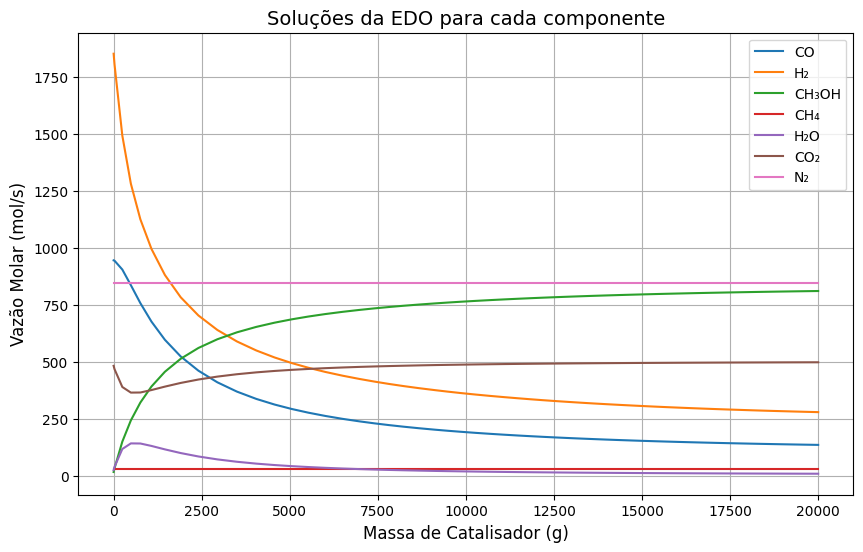

In [ ]:
import matplotlib.pyplot as plt

# Extraindo os tempos (ou massas de catalisador)
tempo = solucao.t

# Extraindo as soluções para cada componente
vazao_CO = solucao.y[0]
vazao_H2 = solucao.y[1]
vazao_CH3OH = solucao.y[2]
vazao_CH4 = solucao.y[3]
vazao_H2O = solucao.y[4]
vazao_CO2 = solucao.y[5]
vazao_N2 = solucao.y[6]

# Plotando os resultados
plt.figure(figsize=(10, 6))

plt.plot(tempo, vazao_CO, label="CO")
plt.plot(tempo, vazao_H2, label="H₂")
plt.plot(tempo, vazao_CH3OH, label="CH₃OH")
plt.plot(tempo, vazao_CH4, label="CH₄")
plt.plot(tempo, vazao_H2O, label="H₂O")
plt.plot(tempo, vazao_CO2, label="CO₂")
plt.plot(tempo, vazao_N2, label="N₂")

# Personalização do gráfico
plt.xlabel('Massa de Catalisador (g)', fontsize=12)
plt.ylabel('Vazão Molar (mol/s)', fontsize=12)
plt.title('Soluções da EDO para cada componente', fontsize=14)
plt.legend()
plt.grid(True)

# Mostrar gráfico
plt.show()
